# Etapa 1 — Árvore de decisão ID3

Classificamos **FRP elevada entre focos já detectados** no bioma Amazônia brasileiro,
com dados do Programa Queimadas/INPE e sensor AQUA_M-T. A unidade é uma detecção em
um pixel e horário, não um incêndio independente nem uma previsão de surgimento de fogo.
FRP é potência radiativa em MW; o rótulo elevado não é uma classificação oficial de dano ambiental.

Os seis atributos são `numero_dias_sem_chuva`, `precipitacao`, `lat`, `lon`, `mes` e
`hora_utc`, na ordem de `utils.ATRIBUTOS`. A classe 1 significa **FRP ≥ Q75 do treino
corrente**. As medianas de imputação/discretização e esse limiar são calculados apenas no treino.
Usamos os cinco folds espaciais de 2024; 2025 permanece reservado ao teste final.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from arvore import entropia, ganho_informacao, aprender_arvore, predizer
from utils import ATRIBUTOS, carregar_dados, iterar_folds, preparar_particao

np.random.seed(42)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 6)

## Verificações didáticas — dados sintéticos

A maioria empatada prevê classe 0; ganhos empatados seguem a ordem original das
colunas. A raiz tem profundidade 0. Não há parada por ganho zero: isso é necessário
para aprender XOR. Categorias são numéricas e já devem estar preparadas antes do ajuste.

In [2]:
assert entropia([]) == 0
assert entropia([1, 1, 1]) == 0
assert np.isclose(entropia([0, 1]), 1)
x_simples = np.array([[0], [0], [1], [1]])
y_simples = np.array([0, 0, 1, 1])
assert np.isclose(ganho_informacao(x_simples[:, 0], y_simples), 1)
a_simples = aprender_arvore(x_simples, y_simples)
assert np.array_equal(predizer(a_simples, x_simples), y_simples)
assert predizer(a_simples, [[2]]).item() == 0
assert aprender_arvore(x_simples, y_simples, profundidade_maxima=0)["folha"]

x_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
a_xor = aprender_arvore(x_xor, y_xor)
assert np.isclose(a_xor["ganho"], 0)
assert np.array_equal(predizer(a_xor, x_xor), y_xor)
assert a_xor["filhos"][0]["atributo"] == 1
assert predizer(a_xor, [[0, 2]]).item() == 0
assert predizer(aprender_arvore([[0], [0], [1]], [1, 1, 0]), [[2]]).item() == 1

for X_invalido, y_invalido in [([], []), ([[0]], [2]), ([[np.nan]], [0]), ([[0]], [0, 1])]:
    try:
        aprender_arvore(X_invalido, y_invalido)
    except ValueError:
        pass
    else:
        raise AssertionError("Entrada inválida aceita.")
print("Verificações sintéticas aprovadas: entropia, ganho, ID3, XOR, profundidade e categorias inéditas.")

Verificações sintéticas aprovadas: entropia, ganho, ID3, XOR, profundidade e categorias inéditas.


## Desenvolvimento de 2024

A leitura confere o hash do produto entregue. As ausências permanecem nesta tabela;
não preparamos os atributos globalmente.

In [3]:
dados = carregar_dados(2024)
assert len(dados) == 140346
assert dados["ano"].eq(2024).all()
display(dados[ATRIBUTOS].describe().T)
display(dados[ATRIBUTOS].isna().sum().rename("ausencias").to_frame())

,count,mean,std,min,25%,50%,75%,max
numero_dias_sem_chuva,138376.0,24.527779,31.897761,0.00000,3.000000,10.000000,30.000000,120.00000
precipitacao,140346.0,0.516689,2.682326,0.00000,0.000000,0.000000,0.000000,119.37000
lat,140346.0,-6.771455,3.810165,-16.27472,-9.308155,-7.345855,-3.797635,5.15566
lon,140346.0,-57.045974,6.494208,-73.65904,-61.230942,-55.950985,-51.994375,-43.75944
mes,140346.0,8.460234,2.111658,1.00000,8.000000,9.000000,10.000000,12.00000
hora_utc,140346.0,18.070197,0.526730,16.55000,17.683333,18.033333,18.400000,19.95000


,ausencias
numero_dias_sem_chuva,1970
precipitacao,0
lat,0
lon,0
mes,0
hora_utc,0


## Uma divisão espacial: fold 0

Categoria 0 significa valor abaixo da mediana do treino; categoria 1 significa
valor igual ou acima dela. Uma coluna pode ficar constante, por exemplo quando
sua mediana é zero e todos os valores são não negativos.

In [4]:
fold, treino, validacao = next(iterar_folds(dados, "espacial"))
p = preparar_particao(treino, validacao, "discretizada")
X_treino, X_validacao = p.X_treino.to_numpy(), p.X_avaliacao.to_numpy()
y_treino, y_validacao = p.y_cls_treino.to_numpy(), p.y_cls_avaliacao.to_numpy()
assert X_treino.shape == (len(treino), 6)
assert X_validacao.shape == (len(validacao), 6)
assert np.isin(X_treino, [0, 1]).all() and np.isin(X_validacao, [0, 1]).all()
assert not set(treino.grupo_validacao) & set(validacao.grupo_validacao)
print(f"Fold {fold}: treino={len(treino):,}; validação={len(validacao):,}; Q75={p.limiar_frp:.3f} MW")
display(pd.DataFrame({"mediana_imputacao": p.parametros["medianas"],
                      "corte_categoria_1": p.parametros["cortes"]}))
display(pd.DataFrame({"treino": np.bincount(y_treino, minlength=2),
                      "validacao": np.bincount(y_validacao, minlength=2)},
                     index=pd.Index([0, 1], name="classe")))

Fold 0: treino=112,277; validação=28,069; Q75=59.500 MW


,mediana_imputacao,corte_categoria_1
numero_dias_sem_chuva,10.00000,10.00000
precipitacao,0.00000,0.00000
lat,-7.67524,-7.67524
lon,-57.61604,-57.61604
mes,9.00000,9.00000
hora_utc,18.10000,18.10000


,treino,validacao
classe,,
0,84172,21714
1,28105,6355


## Comparação nos cinco folds espaciais

Comparamos ID3 e `DecisionTreeClassifier(criterion="entropy")` sem limite de
profundidade, além da maioria do treino. Ambos recebem as mesmas seis colunas
binárias, linhas e classes. O ID3 remove o atributo já utilizado; a referência faz
divisões binárias. Empates podem gerar estruturas diferentes, sem invalidar a comparação.
Não escolhemos profundidade usando as validações.

In [5]:
METRICAS = ["acuracia", "precisao", "recall", "f1"]

def metricas_classificacao(y, previsto):
    return {"acuracia": accuracy_score(y, previsto),
            "precisao": precision_score(y, previsto, zero_division=0),
            "recall": recall_score(y, previsto, zero_division=0),
            "f1": f1_score(y, previsto, zero_division=0)}

def avaliar_arvores(estrategia):
    resultados, exemplo = [], None
    for fold, treino, validacao in iterar_folds(dados, estrategia):
        if estrategia == "espacial":
            assert not set(treino.grupo_validacao) & set(validacao.grupo_validacao)
        else:
            assert treino.data_hora_gmt.max() < validacao.data_hora_gmt.min()
        p = preparar_particao(treino, validacao, "discretizada")
        X, V = p.X_treino.to_numpy(), p.X_avaliacao.to_numpy()
        y, v = p.y_cls_treino.to_numpy(), p.y_cls_avaliacao.to_numpy()
        assert list(p.X_treino.columns) == ATRIBUTOS
        assert np.isclose(p.limiar_frp, treino.frp.quantile(0.75))
        propria = aprender_arvore(X, y, profundidade_maxima=None)
        referencia = DecisionTreeClassifier(criterion="entropy", max_depth=None, random_state=42)
        referencia.fit(X, y)
        previsoes = {"ID3 próprio": predizer(propria, V),
                     "Árvore sklearn": referencia.predict(V),
                     "Maioria do treino": np.full(len(v), np.bincount(y, minlength=2).argmax())}
        for modelo, previsto in previsoes.items():
            assert previsto.shape == v.shape and np.isin(previsto, [0, 1]).all()
            resultados.append({"fold": fold, "modelo": modelo, "limiar_frp_mw": p.limiar_frp,
                               "n_treino": len(y), "n_validacao": len(v),
                               "proporcao_classe_1": v.mean(), **metricas_classificacao(v, previsto)})
        if fold == 0:
            exemplo = {"arvore": propria, "X": X, "y": y, "v": v,
                       "previsoes": previsoes, "parametros": p.parametros, "limiar": p.limiar_frp}
    return pd.DataFrame(resultados), exemplo

resultados_espaciais, exemplo = avaliar_arvores("espacial")
assert len(resultados_espaciais) == 15
assert resultados_espaciais.fold.nunique() == 5
display(resultados_espaciais)

,fold,modelo,limiar_frp_mw,n_treino,n_validacao,proporcao_classe_1,acuracia,precisao,recall,f1
0,0,ID3 próprio,59.5,112277,28069,0.226406,0.773024,0.441176,0.009441,0.018487
1,0,Árvore sklearn,59.5,112277,28069,0.226406,0.773024,0.441176,0.009441,0.018487
2,0,Maioria do treino,59.5,112277,28069,0.226406,0.773594,0.000000,0.000000,0.000000
3,1,ID3 próprio,58.0,112277,28069,0.259290,0.738787,0.443038,0.028854,0.054180
4,1,Árvore sklearn,58.0,112277,28069,0.259290,0.738787,0.443038,0.028854,0.054180
5,1,Maioria do treino,58.0,112277,28069,0.259290,0.740710,0.000000,0.000000,0.000000
6,2,ID3 próprio,58.6,112276,28070,0.246740,0.753260,0.000000,0.000000,0.000000
7,2,Árvore sklearn,58.6,112276,28070,0.246740,0.753260,0.000000,0.000000,0.000000
8,2,Maioria do treino,58.6,112276,28070,0.246740,0.753260,0.000000,0.000000,0.000000
9,3,ID3 próprio,57.9,112277,28069,0.261819,0.738893,0.537879,0.019322,0.037305


## Síntese espacial e matriz de confusão

Cada fold tem o mesmo peso na média. O desvio-padrão é **amostral (`ddof=1`)**,
calculado entre os cinco folds; não é intervalo de confiança. Precisão, recall e
F1 se referem à classe 1. A matriz abaixo usa somente a validação do fold espacial 0.

acuracia           precisao              recall            \
                       mean       std     mean       std      mean       std   
modelo                                                                         
ID3 próprio        0.749312  0.014511  0.36512  0.210052  0.012801  0.011364   
Árvore sklearn     0.749312  0.014511  0.36512  0.210052  0.012801  0.011364   
Maioria do treino  0.749825  0.014465  0.00000  0.000000  0.000000  0.000000   

                         f1            
                       mean       std  
modelo                                 
ID3 próprio        0.024509  0.021351  
Árvore sklearn     0.024509  0.021351  
Maioria do treino  0.000000  0.000000

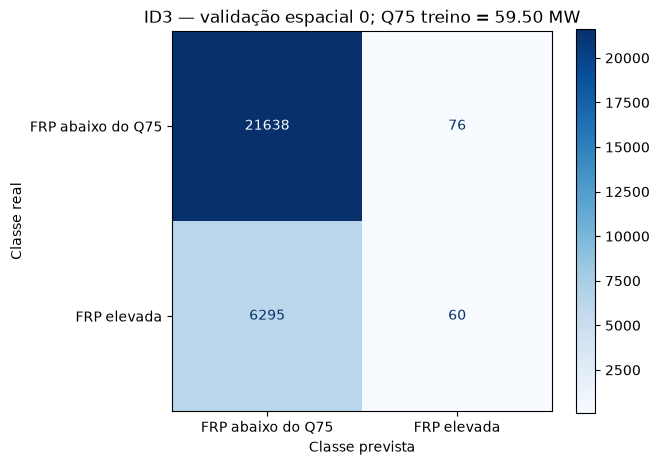

In [6]:
resumo_espacial = resultados_espaciais.groupby("modelo", sort=False)[METRICAS].agg(["mean", "std"])
display(resumo_espacial)
matriz = confusion_matrix(exemplo["v"], exemplo["previsoes"]["ID3 próprio"], labels=[0, 1])
ConfusionMatrixDisplay(matriz, display_labels=["FRP abaixo do Q75", "FRP elevada"]).plot(cmap="Blues")
plt.title(f"ID3 — validação espacial 0; Q75 treino = {exemplo['limiar']:.2f} MW")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

## Entropia e ganho nas profundidades 0, 1 e 2

Auditamos a árvore própria do **treino espacial 0**. Para cada nó, substituímos as
contagens em $H=-\sum_{c:p_c>0}p_c\log_2(p_c)$. A tabela mostra os ganhos de todos os
atributos ainda candidatos, inclusive os constantes. Para a divisão escolhida,
mostramos os filhos, suas entropias, a média ponderada e a subtração do ganho.
Categorias 0/1 usam os cortes exibidos anteriormente. Cada caminho identifica um
nó distinto, mesmo quando dois nós usam o mesmo atributo.

In [7]:
def expressao_entropia(classes):
    contagens = np.bincount(classes, minlength=2)
    n = len(classes)
    termos = [f"({nc}/{n}) log₂({nc}/{n})" for nc in contagens if nc]
    return "−[" + " + ".join(termos) + f"] = {entropia(classes):.8f} bits"

def explicar_niveis(no, X, y, candidatos, profundidade=0, caminho="raiz"):
    if profundidade > 2:
        return
    n0, n1 = no["contagens"]
    assert len(y) == no["n"] and [int((y == c).sum()) for c in [0, 1]] == [n0, n1]
    display(Markdown(f"### Profundidade {profundidade} — {caminho}\n\n"
                     f"n={len(y)}, n0={n0}, n1={n1}; maioria={no['classe']}.  \n"
                     f"H = {expressao_entropia(y)}"))
    if no["folha"]:
        display(Markdown(f"**Folha:** {no['motivo']}; previsão {no['classe']}."))
        return
    j = no["atributo"]
    ganhos = [ganho_informacao(X[:, k], y) for k in candidatos]
    display(pd.DataFrame({"atributo_candidato": [ATRIBUTOS[k] for k in candidatos],
                          "ganho_bits": ganhos, "escolhido": [k == j for k in candidatos]}))
    assert j == candidatos[int(np.argmax(ganhos))]
    linhas, parcelas = [], []
    for valor, filho in no["filhos"].items():
        grupo = X[:, j] == valor
        yf = y[grupo]
        h = entropia(yf)
        linhas.append({"categoria": int(valor), "n": len(yf),
                       "n0": int((yf == 0).sum()), "n1": int((yf == 1).sum()),
                       "H_bits": h, "peso": len(yf) / len(y)})
        parcelas.append(f"({len(yf)}/{len(y)}) × {h:.8f}")
        display(Markdown(f"Filho {ATRIBUTOS[j]}={int(valor)}: H = {expressao_entropia(yf)}"))
    display(pd.DataFrame(linhas))
    ponderada = sum(l["peso"] * l["H_bits"] for l in linhas)
    assert np.isclose(entropia(y) - ponderada, no["ganho"])
    display(Markdown(f"**Escolha: {ATRIBUTOS[j]}**, respeitando a ordem em empates.  \n"
                     f"H dos filhos = {' + '.join(parcelas)} = {ponderada:.8f} bits.  \n"
                     f"Ganho = {entropia(y):.8f} − {ponderada:.8f} = {no['ganho']:.8f} bits."))
    restantes = [k for k in candidatos if k != j]
    for valor, filho in no["filhos"].items():
        grupo = X[:, j] == valor
        explicar_niveis(filho, X[grupo], y[grupo], restantes, profundidade + 1,
                        f"{caminho} → {ATRIBUTOS[j]}={int(valor)}")

explicar_niveis(exemplo["arvore"], exemplo["X"], exemplo["y"], list(range(6)))

### Profundidade 0 — raiz

n=112277, n0=84172, n1=28105; maioria=0.  
H = −[(84172/112277) log₂(84172/112277) + (28105/112277) log₂(28105/112277)] = 0.81178240 bits

,atributo_candidato,ganho_bits,escolhido
0,numero_dias_sem_chuva,0.014286,True
1,precipitacao,0.000000,False
2,lat,0.004705,False
3,lon,0.000091,False
4,mes,0.003209,False
5,hora_utc,0.000065,False


Filho numero_dias_sem_chuva=0: H = −[(43487/53477) log₂(43487/53477) + (9990/53477) log₂(9990/53477)] = 0.69474880 bits

Filho numero_dias_sem_chuva=1: H = −[(40685/58800) log₂(40685/58800) + (18115/58800) log₂(18115/58800)] = 0.89094264 bits

,categoria,n,n0,n1,H_bits,peso
0,0,53477,43487,9990,0.694749,0.476295
1,1,58800,40685,18115,0.890943,0.523705


**Escolha: numero_dias_sem_chuva**, respeitando a ordem em empates.  
H dos filhos = (53477/112277) × 0.69474880 + (58800/112277) × 0.89094264 = 0.79749645 bits.  
Ganho = 0.81178240 − 0.79749645 = 0.01428595 bits.

... (32 outputs left out)

Filho mes=0: H = −[(10081/14639) log₂(10081/14639) + (4558/14639) log₂(4558/14639)] = 0.89473719 bits

Filho mes=1: H = −[(8842/10983) log₂(8842/10983) + (2141/10983) log₂(2141/10983)] = 0.71168708 bits

,categoria,n,n0,n1,H_bits,peso
0,0,14639,10081,4558,0.894737,0.571345
1,1,10983,8842,2141,0.711687,0.428655


**Escolha: mes**, respeitando a ordem em empates.  
H dos filhos = (14639/25622) × 0.89473719 + (10983/25622) × 0.71168708 = 0.81627183 bits.  
Ganho = 0.82893406 − 0.81627183 = 0.01266223 bits.

## Novos exemplos e revisão da hipótese

A demonstração a seguir é **sintética**, com classes fixas: não recalculamos Q75,
não mudamos a representação e não a usamos como evidência sobre incêndios reais.
O ramo X=0 começa com uma observação de cada classe e prevê 0 pelo desempate.
Ao acrescentar um exemplo X=0 com classe 1, a maioria desse ramo muda para 1.

In [8]:
X_antes, y_antes = np.array([[0], [0], [1]]), np.array([0, 1, 1])
X_depois, y_depois = np.vstack([X_antes, [0]]), np.append(y_antes, 1)
antes = predizer(aprender_arvore(X_antes, y_antes), [[0]]).item()
depois = predizer(aprender_arvore(X_depois, y_depois), [[0]]).item()
assert (antes, depois) == (0, 1)
display(pd.DataFrame({"momento": ["antes", "depois"], "n_no_X0": [2, 3],
                      "n0": [1, 1], "n1": [1, 2], "previsao_X0": [antes, depois]}))

,momento,n_no_X0,n0,n1,previsao_X0
0,antes,2,1,1,0
1,depois,3,1,2,1


A aprendizagem indutiva escolhe uma hipótese a partir de um conjunto finito de
observações. No ID3, a escolha dos atributos depende das frequências de classes
e dos ganhos de informação; a previsão de uma folha depende de sua maioria.
Novas observações podem modificar tanto as divisões quanto as maiorias. Portanto,
uma previsão aprendida não precisa permanecer válida após o reajuste com mais
dados. O exemplo torna essa revisão verificável: a conclusão para X=0 muda de 0
para 1, embora todas as observações anteriores continuem no treino e seus rótulos
permaneçam exatamente os mesmos.

Nesse sentido, o procedimento de aprendizagem é revisável e suas conclusões podem
ser chamadas de não monotônicas: acrescentar evidência pode levar ao abandono de
uma hipótese anterior. Mesmo uma árvore sem poda conserva essa possibilidade,
porque entradas iguais com classes distintas não podem ser separadas apenas pelo
atributo disponível. A regra de maioria resolve o conflito localmente, mas depende
do conjunto observado. Uma mudança assim não exige erro de implementação nem
alteração da definição do alvo.

Isso deve ser distinguido da monotonicidade da consequência lógica clássica.
Se uma conclusão é consequência lógica de premissas em um sistema monotônico,
adicionar premissas preserva essa consequência. O ID3 não demonstrou uma conclusão
necessária a partir de axiomas: estimou uma regularidade por indução. Reajustar
essa regularidade com novas frequências constitui revisão de uma hipótese, não
uma refutação da monotonicidade da lógica clássica. No estudo real, mudanças no
Q75 do treino seriam ainda outra fonte de mudança de rótulo; por isso o exemplo
mantém as classes fixas para isolar somente a revisão da árvore.

## Diagnóstico temporal complementar

Escolha do projeto: treinar nos meses anteriores e validar no bimestre seguinte,
conforme os cinco folds temporais já entregues. Municípios podem reaparecer,
enquanto o treino sempre precede a validação. As transformações e o Q75 são
reaprendidos em cada treino. Esta tabela fica separada da espacial: os protocolos
medem dificuldades diferentes e não formam uma validação de dez folds.

In [9]:
resultados_temporais, _ = avaliar_arvores("temporal")
assert resultados_temporais.fold.nunique() == 5
display(resultados_temporais)
resumo_temporal = resultados_temporais.groupby("modelo", sort=False)[METRICAS].agg(["mean", "std"])
display(resumo_temporal)

,fold,modelo,limiar_frp_mw,n_treino,n_validacao,proporcao_classe_1,acuracia,precisao,recall,f1
0,0,ID3 próprio,40.9,5206,3771,0.176611,0.844869,0.686636,0.223724,0.337486
1,0,Árvore sklearn,40.9,5206,3771,0.176611,0.844869,0.686636,0.223724,0.337486
2,0,Maioria do treino,40.9,5206,3771,0.176611,0.823389,0.000000,0.000000,0.000000
3,1,ID3 próprio,36.8,8977,4512,0.341090,0.658466,0.000000,0.000000,0.000000
4,1,Árvore sklearn,36.8,8977,4512,0.341090,0.658466,0.000000,0.000000,0.000000
5,1,Maioria do treino,36.8,8977,4512,0.341090,0.658910,0.000000,0.000000,0.000000
6,2,ID3 próprio,40.5,13489,49700,0.431449,0.590141,0.777835,0.070046,0.128519
7,2,Árvore sklearn,40.5,13489,49700,0.431449,0.590141,0.777835,0.070046,0.128519
8,2,Maioria do treino,40.5,13489,49700,0.431449,0.568551,0.000000,0.000000,0.000000
9,3,ID3 próprio,65.7,63189,57632,0.222134,0.777866,0.500000,0.021325,0.040905


acuracia            precisao              recall            \
                       mean       std      mean       std      mean       std   
modelo                                                                          
ID3 próprio        0.746407  0.118214  0.413947  0.346705  0.063316  0.094036   
Árvore sklearn     0.746407  0.118214  0.413947  0.346705  0.063316  0.094036   
Maioria do treino  0.738189  0.121739  0.000000  0.000000  0.000000  0.000000   

                         f1            
                       mean       std  
modelo                                 
ID3 próprio        0.101968  0.141517  
Árvore sklearn     0.101968  0.141517  
Maioria do treino  0.000000  0.000000

## Discussão dos resultados

O ID3 próprio e a árvore do scikit-learn apresentaram as mesmas métricas nos cinco
folds espaciais: acurácia média de **0,749312**, com desvio-padrão amostral de
**0,014511**. A maioria do treino obteve **0,749825**, ligeiramente acima das árvores.
Portanto, a acurácia próxima de 75% não demonstra capacidade útil de identificar
FRP elevada. A classe 1 corresponde aproximadamente ao quartil superior do treino;
com esse desequilíbrio, prever quase sempre 0 já produz acurácia alta. O recall médio
das árvores foi **0,012801** e o F1 médio **0,024509**: poucos positivos foram recuperados.

Os testes sintéticos, incluindo XOR e categoria inédita, verificam as regras do
algoritmo; a comparação real confere seu uso nas mesmas partições da biblioteca.
Os cálculos das profundidades 0–2 explicam a escolha por ganho de informação sem
recorrer a uma medida de impureza pronta. A discretização facilita a demonstração,
mas perde informação: no fold 0, precipitação tem corte zero e torna-se constante.
Isso ajuda a entender a limitação da representação, sem provar a causa de todo o
baixo recall. Nenhum desempenho foi ajustado para corresponder às faixas do gabarito.

No diagnóstico temporal, as árvores obtiveram acurácia média **0,746407**, desvio
**0,118214** e recall **0,063316**, enquanto a maioria obteve acurácia **0,738189**.
A variação maior evidencia sensibilidade ao período e ao Q75 de cada treino, mas
não deve ser agregada aos folds espaciais. Detecções próximas podem ser dependentes,
mesmo em municípios diferentes, e horário do sensor, nuvens e ausências de atributos
limitam a interpretação. Estas métricas descrevem somente 2024 e focos já detectados;
não medem dano ambiental nem antecipação de incêndios. O teste de 2025 permanece fechado.

## Conferência final

Executar **Reiniciar kernel e executar todas as células** no kernel **FIA (Python 3.12)**
e salvar este notebook. Todas as tabelas, contas e figuras permanecem nas saídas;
nenhum relatório ou resultado externo é produzido.

In [10]:
assert dados.ano.eq(2024).all()
assert len(resultados_espaciais) == len(resultados_temporais) == 15
assert np.isfinite(resultados_espaciais[METRICAS].to_numpy()).all()
assert np.isfinite(resultados_temporais[METRICAS].to_numpy()).all()
print("Etapa 1 concluída: testes sintéticos, cinco folds espaciais, cinco temporais e cálculos dos três níveis.")

Etapa 1 concluída: testes sintéticos, cinco folds espaciais, cinco temporais e cálculos dos três níveis.
